# Clustering: K-Means, Hierarchical Clustering, and DBSCAN

Clustering is unsupervised learning: there are no labels, and the goal is to discover groups of
similar samples. This notebook compares three widely used algorithms:

- **K-Means** - partitions data into `k` spherical clusters by minimising within-cluster variance.
- **Agglomerative (hierarchical) clustering** - repeatedly merges the closest clusters and produces
  a dendrogram.
- **DBSCAN** - finds dense regions separated by sparse regions and labels low-density points as noise.

## Learning objectives

1. Explain the K-Means objective and the effect of `k`.
2. Choose `k` with the elbow method and silhouette score.
3. Read a dendrogram and choose a cut height.
4. Use DBSCAN to find arbitrarily shaped clusters and identify noise.
5. Evaluate clustering with silhouette, Davies-Bouldin, and adjusted Rand index when labels exist.

## 1. Concepts

### K-Means

K-Means minimises the inertia:

$$J = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

where $\mu_{c(i)}$ is the centroid of the cluster assigned to point $i$.

- It assumes roughly spherical, similarly sized clusters.
- It requires `k` in advance.
- Results depend on initialisation; `n_init` restarts help.
- Scaling is required because it uses Euclidean distance.

### Hierarchical clustering

- Bottom-up (agglomerative) starts with one cluster per point and merges the closest pairs.
- The dendrogram shows the merge order; cutting it at a chosen height produces clusters.
- Linkage choices (`ward`, `complete`, `average`, `single`) change the result.
- Cost grows quickly with dataset size.

### DBSCAN

- Groups points that have at least `min_samples` neighbours within radius `eps`.
- Finds clusters of arbitrary shape and marks sparse points as noise.
- Does not require `k`, but `eps` and `min_samples` are sensitive.
- Struggles when clusters have very different densities.

### Evaluation without labels

- **Silhouette score**: how much closer a point is to its own cluster than to the next closest one.
  Range -1 to 1; higher is better.
- **Davies-Bouldin index**: average similarity between clusters; lower is better.
- **Adjusted Rand index (ARI)**: compares discovered clusters with known labels; 1 is perfect, 0 is random.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Generate blob data

Four well-separated blobs make the behaviour of K-Means and hierarchical clustering easy to see.

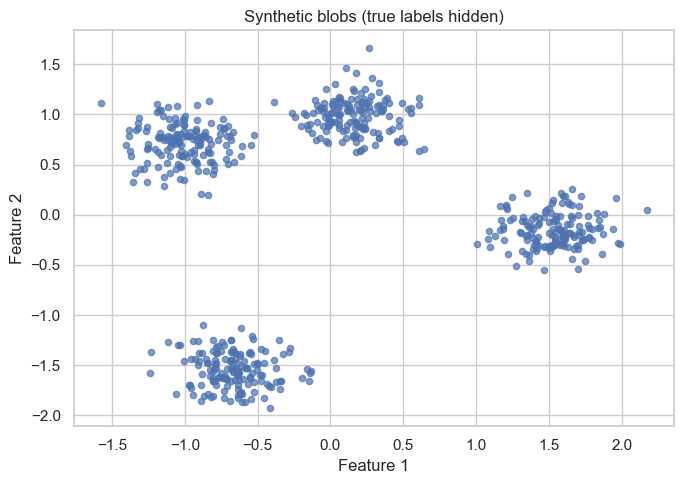

In [2]:
X_blobs, y_blobs = make_blobs(
    n_samples=600,
    centers=4,
    cluster_std=1.1,
    random_state=RANDOM_STATE,
)
X_blobs = StandardScaler().fit_transform(X_blobs)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], s=20, alpha=0.7)
plt.title("Synthetic blobs (true labels hidden)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

## 4. K-Means: elbow method

Inertia always decreases as `k` grows, so it cannot be minimised directly. The "elbow" is the point
where adding another cluster gives diminishing improvement.

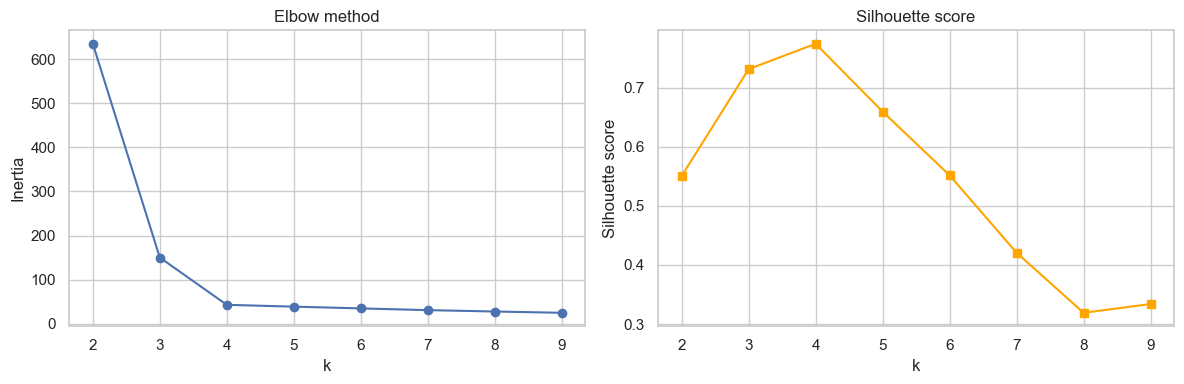

In [3]:
k_values = range(2, 10)
inertias = []
silhouettes = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_blobs)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_blobs, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow method")

axes[1].plot(list(k_values), silhouettes, marker="s", color="orange")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")

plt.tight_layout()
plt.show()

### Fit K-Means with the chosen `k`

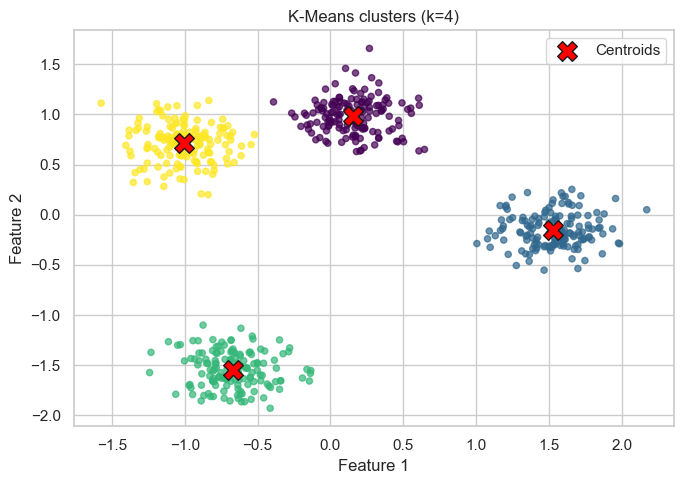

Silhouette: 0.7741
Davies-Bouldin: 0.3169
ARI vs true labels: 0.9955


In [4]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans.fit_predict(X_blobs)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_kmeans, cmap="viridis", s=20, alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            marker="X", s=200, color="red", edgecolor="k", label="Centroids")
plt.title("K-Means clusters (k=4)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print("Silhouette:", round(silhouette_score(X_blobs, labels_kmeans), 4))
print("Davies-Bouldin:", round(davies_bouldin_score(X_blobs, labels_kmeans), 4))
print("ARI vs true labels:", round(adjusted_rand_score(y_blobs, labels_kmeans), 4))

## 5. Hierarchical clustering

The dendrogram below visualises the merge sequence. A horizontal cut at a large gap suggests a
natural number of clusters.

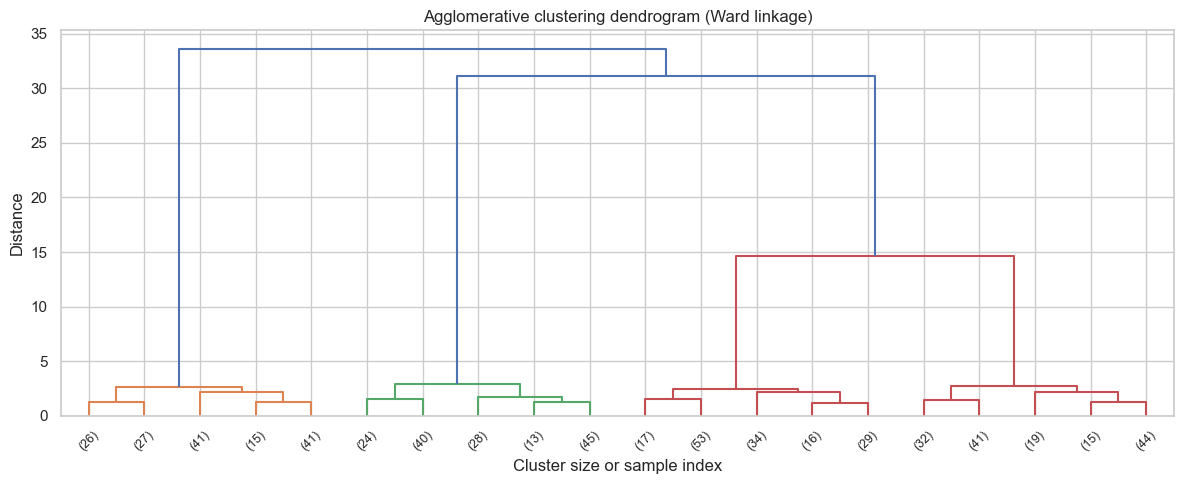

In [5]:
linkage_matrix = linkage(X_blobs, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linkage_matrix, truncate_mode="lastp", p=20, leaf_rotation=45, leaf_font_size=9)
plt.title("Agglomerative clustering dendrogram (Ward linkage)")
plt.xlabel("Cluster size or sample index")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

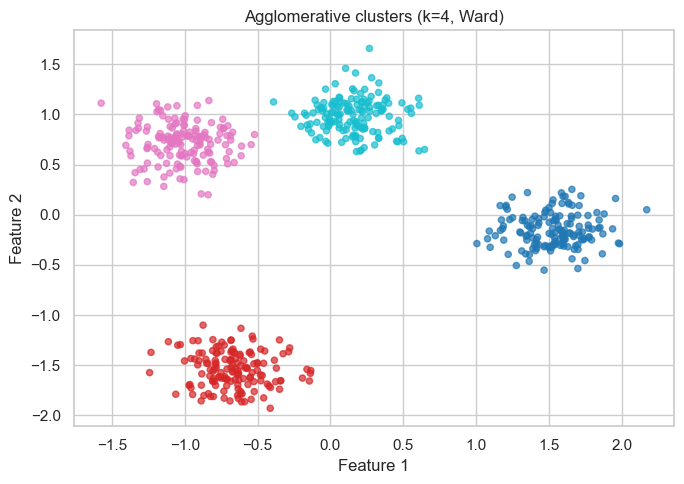

Silhouette: 0.7741
ARI vs true labels: 0.9955


In [6]:
hierarchical = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_hier = hierarchical.fit_predict(X_blobs)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_hier, cmap="tab10", s=20, alpha=0.7)
plt.title("Agglomerative clusters (k=4, Ward)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

print("Silhouette:", round(silhouette_score(X_blobs, labels_hier), 4))
print("ARI vs true labels:", round(adjusted_rand_score(y_blobs, labels_hier), 4))

## 6. DBSCAN on non-spherical data

The two-moons dataset has curved clusters that K-Means would cut incorrectly. DBSCAN can follow the
shape because it grows clusters through dense neighbourhoods.

Clusters: 2 Noise points: 0


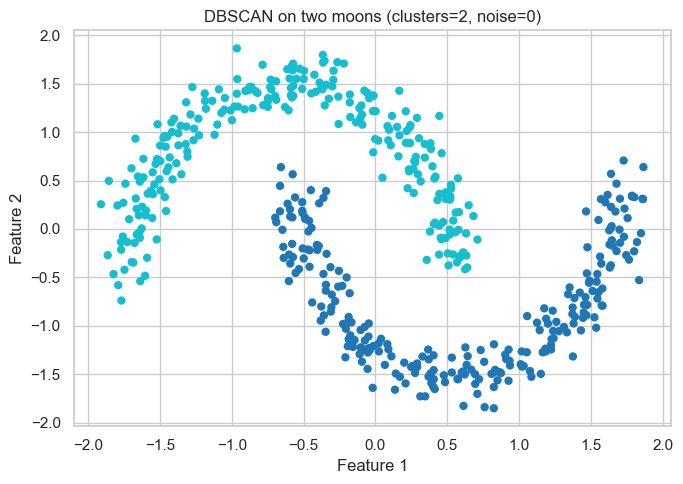

Silhouette (non-noise): 0.3836
ARI vs true labels: 1.0


In [7]:
X_moons, y_moons = make_moons(n_samples=500, noise=0.08, random_state=RANDOM_STATE)
X_moons = StandardScaler().fit_transform(X_moons)

dbscan = DBSCAN(eps=0.3, min_samples=8)
labels_dbscan = dbscan.fit_predict(X_moons)

n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = np.sum(labels_dbscan == -1)
print("Clusters:", n_clusters, "Noise points:", n_noise)

plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_dbscan, cmap="tab10", s=25)
plt.title(f"DBSCAN on two moons (clusters={n_clusters}, noise={n_noise})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

if n_clusters > 1:
    mask = labels_dbscan != -1
    print("Silhouette (non-noise):", round(silhouette_score(X_moons[mask], labels_dbscan[mask]), 4))
print("ARI vs true labels:", round(adjusted_rand_score(y_moons, labels_dbscan), 4))

### How sensitive is DBSCAN to `eps`?

We try several values. Too small and everything becomes noise; too large and clusters merge.

In [8]:
rows = []
for eps in [0.15, 0.2, 0.3, 0.4, 0.5]:
    labels = DBSCAN(eps=eps, min_samples=8).fit_predict(X_moons)
    clusters = len(set(labels)) - (1 if -1 in labels else 0)
    rows.append({
        "eps": eps,
        "clusters": clusters,
        "noise_points": int(np.sum(labels == -1)),
        "ari": round(adjusted_rand_score(y_moons, labels), 4),
    })
pd.DataFrame(rows)

,eps,clusters,noise_points,ari
0,0.15,13,50,0.2264
1,0.20,2,7,0.9722
2,0.30,2,0,1.0000
3,0.40,2,0,1.0000
4,0.50,1,0,0.0000


## 7. Comparing the algorithms

| Algorithm | Needs `k`? | Cluster shape | Handles noise? | Scaling | Strength |
| --- | --- | --- | --- | --- | --- |
| K-Means | Yes | Spherical | No (assigns every point) | Required | Fast, simple, scalable |
| Hierarchical | No (cut later) | Depends on linkage | No | Required | Dendrogram, small datasets |
| DBSCAN | No | Arbitrary | Yes | Required | Non-spherical clusters, outliers |

## Key takeaways

- Clustering has no single correct answer; the algorithm and distance metric encode assumptions.
- Scale features before distance-based clustering.
- Use the elbow and silhouette together when choosing `k`.
- DBSCAN is a strong choice for non-spherical clusters and noise, but `eps` needs tuning.
- If labels exist, use ARI; otherwise use silhouette and domain review.

## Exercises

1. Run K-Means on the two-moons data. Why does it fail?
2. Try `linkage="single"` and `linkage="complete"` on the blobs. How does the dendrogram change?
3. Tune `eps` and `min_samples` for DBSCAN on a dataset with varying density.
4. Use PCA to reduce the digits dataset to two dimensions, then cluster it.
5. Explain why silhouette is not reliable for DBSCAN clusters that include noise points.